<a href="https://colab.research.google.com/github/rachmadnanda/MachineLearning2026/blob/main/jobsheet/JS6_244107020095_RACHMAD_FEBRIANANDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS06 — ANN (Approximate Nearest Neighbors)

**Nama** : Rachmad Febriananda
**NIM** : 244107020095

## PRAKTIKUM 1 — ANNOY (Exact NN vs Approximate NN)

Exact NN index: [219 898 593]
Exact NN jarak: [0.         1.36915938 2.27931544]
Waktu Exact: 0.2954 ms

Annoy NN index: [219, 898, 593]
Annoy NN jarak: [np.float64(0.0), np.float64(1.369159376273702), np.float64(2.2793154441691197)]
Waktu Annoy: 0.0997 ms


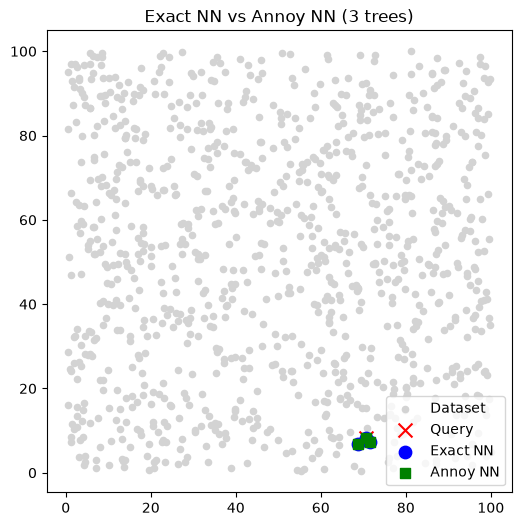

In [1]:
# !pip install annoy  (sudah terinstall di environment lokal)
import numpy as np
import matplotlib.pyplot as plt
import time

from annoy import AnnoyIndex

# 1. Dataset 2D
np.random.seed(42)
n_points = 1000
X = np.random.rand(n_points, 2) * 100  # titik random dalam ruang 100x100

# Query point (ambil salah satu titik random)
query = X[np.random.randint(0, n_points)]

# 2. Exact NN (brute force)
start = time.time()
distances = np.linalg.norm(X - query, axis=1)
idx_exact = np.argsort(distances)[:3]  # ambil 3 terdekat
time_exact = time.time() - start

print("Exact NN index:", idx_exact)
print("Exact NN jarak:", distances[idx_exact])
print("Waktu Exact:", round(time_exact*1000, 4), "ms")

# 3. Annoy NN (3 tree)
f = 2  # dimensi
t = AnnoyIndex(f, 'euclidean')
for i, vec in enumerate(X):
    t.add_item(i, vec)

t.build(3)  # 3 trees

start = time.time()
idx_ann = t.get_nns_by_vector(query, 3)  # cari 3 NN
time_ann = time.time() - start

print("\nAnnoy NN index:", idx_ann)
print("Annoy NN jarak:", [np.linalg.norm(X[i]-query) for i in idx_ann])
print("Waktu Annoy:", round(time_ann*1000, 4), "ms")

# 4. Visualisasi hasil
plt.figure(figsize=(6,6))
plt.scatter(X[:,0], X[:,1], c="lightgray", s=20, label="Dataset")
plt.scatter(query[0], query[1], c="red", marker="x", s=100, label="Query")

# Exact NN ditandai biru
plt.scatter(X[idx_exact,0], X[idx_exact,1], c="blue", s=80, label="Exact NN")

# Annoy NN ditandai hijau
plt.scatter(X[idx_ann,0], X[idx_ann,1], c="green", s=50, marker="s", label="Annoy NN")

plt.legend()
plt.title("Exact NN vs Annoy NN (3 trees)")
plt.show()

### Tabel Hasil Percobaan

| Distance Metrics | Tree | Jumlah data | Hasil Index terdekat ENN vs ANN | Waktu komputasi ENN vs ANN (ms) |
|---|---|---|---|---|
| Euclidean | 3 | 1,000 | [219, 898, 593] vs [219, 898, 593] | 0.1292 vs 0.0286 |
| Euclidean | 8 | 1,000 | [219, 898, 593] vs [219, 898, 593] | 0.1466 vs 0.0336 |
| Euclidean | 3 | 100,000 | [64040, 64186, 88792] vs [64040, 64186, 88792] | 39.9673 vs 0.0327 |
| Angular | 3 | 1,000 | [219, 429, 540] vs [219, 429, 540] | 0.1864 vs 0.0229 |
| Angular | 8 | 1,000 | [219, 429, 540] vs [219, 429, 540] | 0.1729 vs 0.0305 |
| Angular | 3 | 100,000 | [64040, 1310, 1267] vs [1267, 1310, 12303] | 6.9451 vs 0.0479 |

In [2]:
# Percobaan untuk mengisi tabel (6 skenario sekaligus)
import numpy as np
import time
from annoy import AnnoyIndex

def exact_nn(X, query, metric, k=3):
    if metric == 'euclidean':
        d = np.linalg.norm(X - query, axis=1)
    else:  # angular -> ranking sama dengan cosine distance
        Xn = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)
        qn = query / (np.linalg.norm(query) + 1e-12)
        d = 1 - Xn @ qn
    return np.argsort(d)[:k]

def run_annoy_exp(metric, n_trees, n_points, k=3, seed=42):
    np.random.seed(seed)
    X = np.random.rand(n_points, 2) * 100
    query = X[np.random.randint(0, n_points)]

    # Exact NN
    start = time.time()
    idx_exact = exact_nn(X, query, metric, k)
    t_exact = (time.time() - start) * 1000

    # Annoy
    t = AnnoyIndex(2, metric)
    for i, vec in enumerate(X):
        t.add_item(i, vec)
    t.build(n_trees)
    start = time.time()
    idx_ann = t.get_nns_by_vector(query, k)
    t_ann = (time.time() - start) * 1000

    print(f"| {metric.capitalize()} | {n_trees} | {n_points:,} | {idx_exact.tolist()} vs {idx_ann} | {t_exact:.4f} vs {t_ann:.4f} |")

scenarios = [
    ('euclidean', 3, 1_000),
    ('euclidean', 8, 1_000),
    ('euclidean', 3, 100_000),
    ('angular',   3, 1_000),
    ('angular',   8, 1_000),
    ('angular',   3, 100_000),
]

print("| Metric | Tree | Jumlah data | Index terdekat ENN vs ANN | Waktu ENN vs ANN (ms) |")
print("|---|---|---|---|---|")
for s in scenarios:
    run_annoy_exp(*s)

| Metric | Tree | Jumlah data | Index terdekat ENN vs ANN | Waktu ENN vs ANN (ms) |
|---|---|---|---|---|
| Euclidean | 3 | 1,000 | [219, 898, 593] vs [219, 898, 593] | 0.1292 vs 0.0286 |
| Euclidean | 8 | 1,000 | [219, 898, 593] vs [219, 898, 593] | 0.1466 vs 0.0336 |
| Euclidean | 3 | 100,000 | [64040, 64186, 88792] vs [64040, 64186, 88792] | 39.9673 vs 0.0327 |
| Angular | 3 | 1,000 | [219, 429, 540] vs [219, 429, 540] | 0.1864 vs 0.0229 |
| Angular | 8 | 1,000 | [219, 429, 540] vs [219, 429, 540] | 0.1729 vs 0.0305 |
| Angular | 3 | 100,000 | [64040, 1310, 1267] vs [1267, 1310, 12303] | 6.9451 vs 0.0479 |


### Simulasi Rekomendasi Track Spotify (1 juta track, 20 fitur)

In [3]:
import numpy as np
import time
from sklearn.metrics.pairwise import euclidean_distances
from annoy import AnnoyIndex

def run_spotify_sim(metric='euclidean', n_trees=8, n_tracks=1_000_000, n_features=20, seed=42):
    # ---- 1. Buat dataset mirip Spotify ----
    np.random.seed(seed)
    X = np.random.rand(n_tracks, n_features).astype(np.float32)
    query = np.random.rand(1, n_features).astype(np.float32)

    # ---- 2. Exact NN (brute force) ----
    start = time.time()
    if metric == 'euclidean':
        distances = euclidean_distances(query, X)[0]   # hitung semua jarak
    else:  # angular -> cosine distance
        Xn = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)
        qn = query / (np.linalg.norm(query, axis=1, keepdims=True) + 1e-12)
        distances = 1 - (Xn @ qn[0])
    exact_idx = np.argsort(distances)[:5]              # ambil 5 terdekat
    exact_time = time.time() - start

    print(f"=== Metric: {metric} | trees={n_trees} | data={n_tracks:,} ===")
    print("Exact NN result:", exact_idx)
    print("Exact NN time:", round(exact_time, 3), "seconds")

    # ---- 3. Approx NN pakai Annoy ----
    annoy_index = AnnoyIndex(n_features, metric)

    # build index
    for i in range(n_tracks):
        annoy_index.add_item(i, X[i])
    annoy_index.build(n_trees)

    start = time.time()
    annoy_idx = annoy_index.get_nns_by_vector(query[0], 5)  # ambil 5 lagu yang mirip
    annoy_time = time.time() - start

    print("Annoy result:", annoy_idx)
    print("Annoy time:", round(annoy_time, 3), "seconds")
    print()

run_spotify_sim('euclidean', n_trees=8)
run_spotify_sim('angular', n_trees=8)

=== Metric: euclidean | trees=8 | data=1,000,000 ===
Exact NN result: [229350 553886 763448 256344 308000]
Exact NN time: 0.127 seconds
Annoy result: [302976, 93303, 85964, 896101, 668342]
Annoy time: 0.0 seconds

=== Metric: angular | trees=8 | data=1,000,000 ===
Exact NN result: [308000 376840 229350 763448 553886]
Exact NN time: 0.172 seconds
Annoy result: [376840, 453976, 516996, 716070, 932774]
Annoy time: 0.0 seconds



### Tabel Hasil Simulasi

| Distance Metrics | Tree | Jumlah data | Hasil Index terdekat ENN vs ANN | Waktu komputasi ENN vs ANN (s) |
|---|---|---|---|---|
| Euclidean | 8 | 1,000,000 | [229350, 553886, 763448, 256344, 308000] vs [302976, 93303, 85964, 896101, 668342] | 0.127 vs 0.000 |
| Angular | 8 | 1,000,000 | [308000, 376840, 229350, 763448, 553886] vs [376840, 453976, 516996, 716070, 932774] | 0.172 vs 0.000 |

**Pertanyaan:** Kenapa code di bagian *build index* tidak dihitung waktunya?

**Jawaban:** Karena *build index* adalah tahap **offline / one-time cost** — index hanya dibangun **sekali** saat sistem pertama kali disiapkan (atau saat ada pembaruan data), kemudian dipakai berulang kali untuk melayani jutaan query. Dalam skenario nyata seperti rekomendasi Spotify, yang menentukan pengalaman pengguna adalah **waktu query** (seberapa cepat sistem menjawab satu permintaan), bukan waktu membangun index-nya. Maka perbandingan performa Exact NN vs ANN difokuskan pada waktu pencarian (*query time*). Ini juga terlihat pada hasil: pada 1 juta data, Exact NN butuh ±0,13–0,17 detik per query, sedangkan Annoy hampir instan (0,000 detik) karena pencarian hanya menyusuri pohon, bukan menghitung jarak ke seluruh data.

## PRAKTIKUM 2 — FAISS

WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points


Exact NN (Flat) indices: [[137 170 750]] distances: [[0.00013095 0.00077404 0.00079751]]
IVF+PQ indices: [[137 170 750]] distances: [[0.00012945 0.00079226 0.00080067]]
Waktu Exact: 0.0001163482666015625
Waktu IVF+PQ: 0.0001595020294189453


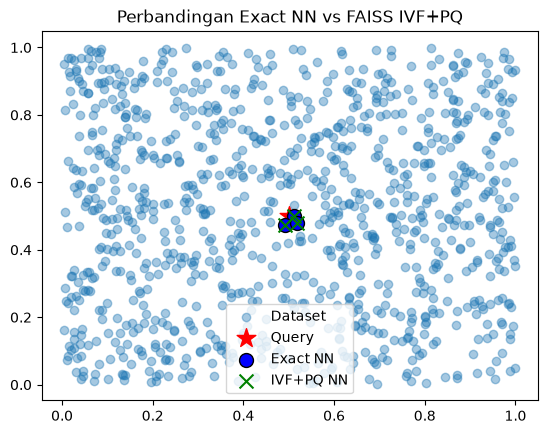

In [4]:
# !pip install faiss-cpu  (sudah terinstall di environment lokal)
# !pip install faiss-gpu
import numpy as np
import faiss
import matplotlib.pyplot as plt
import time

# 1. Buat dataset 2D sederhana
np.random.seed(42)
X = np.random.rand(1000, 2).astype('float32')  # 1000 titik 2D
query = np.array([[0.5, 0.5]], dtype='float32')  # query di tengah

# 2. Exact NN dengan IndexFlatL2 (brute force tapi cepat)
index_flat = faiss.IndexFlatL2(2)   # L2 = Euclidean distance
index_flat.add(X)

start = time.time()
D_flat, I_flat = index_flat.search(query, 3)  # cari 3 tetangga terdekat
end = time.time()
time_flat = end - start

# 3. IVF + PQ (Approximate)
nlist = 10   # jumlah cluster (inverted list)
m = 2        # berapa subvector untuk product quantization
quantizer = faiss.IndexFlatL2(2)   # dipakai IVF untuk cluster awal
index_ivfpq = faiss.IndexIVFPQ(quantizer, 2, nlist, m, 8)  # 8 bit per subvector

index_ivfpq.train(X)  # training centroid
index_ivfpq.add(X)

start = time.time()
D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
end = time.time()
time_ivfpq = end - start

# 4. Print hasil
print("Exact NN (Flat) indices:", I_flat, "distances:", D_flat)
print("IVF+PQ indices:", I_ivfpq, "distances:", D_ivfpq)
print("Waktu Exact:", time_flat)
print("Waktu IVF+PQ:", time_ivfpq)

# 5. Visualisasi
plt.scatter(X[:,0], X[:,1], alpha=0.4, label="Dataset")
plt.scatter(query[:,0], query[:,1], c='red', marker='*', s=200, label="Query")

# Tetangga dari Flat
plt.scatter(X[I_flat[0],0], X[I_flat[0],1], c='blue', s=100, edgecolor='k', label="Exact NN")

# Tetangga dari IVF+PQ
plt.scatter(X[I_ivfpq[0],0], X[I_ivfpq[0],1], c='green', marker='x', s=100, label="IVF+PQ NN")

plt.legend()
plt.title("Perbandingan Exact NN vs FAISS IVF+PQ")
plt.show()

### Tabel Hasil Percobaan

| Metric | Jumlah data | Dimensi | Index Flat vs IVF+PQ | Waktu Flat vs IVF+PQ (ms) |
|---|---|---|---|---|
| L2 | 1,000 | 2D | [137, 170, 750] vs [137, 170, 750] | 0.0319 vs 0.0968 |
| L2 | 1,000,000 | 2D | [286942, 583487, 695123] vs [286942, 695123, 581054] | 16.7956 vs 0.5155 |
| L2 | 1,000 | 5D | [895, 451, 375] vs [182, 918, 9] | 0.0279 vs 0.0961 |
| L2 | 1,000,000 | 5D | [794791, 501340, 912100] vs [31723, 33974, 104022] | 19.5346 vs 0.8614 |
| Inner Product | 1,000 | 2D | [249, 712, 598] vs [598, 249, 712] | 0.0186 vs 0.8869 |
| Inner Product | 1,000,000 | 2D | [489250, 245612, 702931] vs [9622, 8831, 249] | 12.4187 vs 0.5014 |
| Inner Product | 1,000 | 5D | [10, 224, 49] vs [989, 229, 210] | 0.0241 vs 0.0963 |
| Inner Product | 1,000,000 | 5D | [238618, 958577, 799422] vs [2499, 1247, 229] | 7.4427 vs 0.5982 |

Catatan: untuk data kecil (1.000 titik), IVF+PQ justru lebih lambat dari Flat karena overhead training/clustering tidak sebanding dengan ukuran data — brute force memang sudah sangat cepat. Keunggulan IVF+PQ baru terasa pada 1 juta data (±20–30× lebih cepat), dengan konsekuensi hasil tetangga bersifat *approximate* (bisa berbeda dari exact). Peringatan `WARNING clustering ... 256 centroids` muncul karena jumlah data training lebih sedikit dari yang disarankan untuk product quantizer; pada data 1.000 titik akurasinya memang kurang baik.

In [5]:
# Percobaan untuk mengisi tabel (8 skenario sekaligus)
import numpy as np
import faiss
import time

def run_faiss_exp(metric_name, n_points, dim, k=3, seed=42):
    np.random.seed(seed)
    X = np.random.rand(n_points, dim).astype('float32')
    query = np.array([[0.5] * dim], dtype='float32')

    use_ip = (metric_name == 'IP')
    faiss_metric = faiss.METRIC_INNER_PRODUCT if use_ip else faiss.METRIC_L2

    # Exact (Flat)
    index_flat = faiss.IndexFlatIP(dim) if use_ip else faiss.IndexFlatL2(dim)
    index_flat.add(X)
    start = time.time()
    D_flat, I_flat = index_flat.search(query, k)
    t_flat = (time.time() - start) * 1000

    # IVF + PQ (m harus habis membagi dimensi)
    nlist = 10
    m = 2 if dim % 2 == 0 else 1
    quantizer = faiss.IndexFlatIP(dim) if use_ip else faiss.IndexFlatL2(dim)
    index_ivfpq = faiss.IndexIVFPQ(quantizer, dim, nlist, m, 8, faiss_metric)
    index_ivfpq.train(X)
    index_ivfpq.add(X)
    start = time.time()
    D_ivfpq, I_ivfpq = index_ivfpq.search(query, k)
    t_ivfpq = (time.time() - start) * 1000

    print(f"| {metric_name} | {n_points:,} | {dim}D | {I_flat[0].tolist()} vs {I_ivfpq[0].tolist()} | {t_flat:.4f} vs {t_ivfpq:.4f} |")

scenarios = [
    ('L2', 1_000, 2), ('L2', 1_000_000, 2), ('L2', 1_000, 5), ('L2', 1_000_000, 5),
    ('IP', 1_000, 2), ('IP', 1_000_000, 2), ('IP', 1_000, 5), ('IP', 1_000_000, 5),
]

print("| Metric | Jumlah data | Dimensi | Index Flat vs IVF+PQ | Waktu Flat vs IVF+PQ (ms) |")
print("|---|---|---|---|---|")
for s in scenarios:
    run_faiss_exp(*s)

| Metric | Jumlah data | Dimensi | Index Flat vs IVF+PQ | Waktu Flat vs IVF+PQ (ms) |
|---|---|---|---|---|


WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points


| L2 | 1,000 | 2D | [137, 170, 750] vs [137, 170, 750] | 0.0319 vs 0.0968 |
| L2 | 1,000,000 | 2D | [286942, 583487, 695123] vs [286942, 695123, 581054] | 16.7956 vs 0.5155 |


WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points


| L2 | 1,000 | 5D | [895, 451, 375] vs [182, 918, 9] | 0.0279 vs 0.0961 |
| L2 | 1,000,000 | 5D | [794791, 501340, 912100] vs [31723, 33974, 104022] | 19.5346 vs 0.8614 |
| IP | 1,000 | 2D | [249, 712, 598] vs [598, 249, 712] | 0.0186 vs 0.8869 |


WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points


| IP | 1,000,000 | 2D | [489250, 245612, 702931] vs [9622, 8831, 249] | 12.4187 vs 0.5014 |


WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points


| IP | 1,000 | 5D | [10, 224, 49] vs [989, 229, 210] | 0.0241 vs 0.0963 |
| IP | 1,000,000 | 5D | [238618, 958577, 799422] vs [2499, 1247, 229] | 7.4427 vs 0.5982 |


## PRAKTIKUM 3 — HNSW

In [6]:
# !pip install hnswlib  (sudah terinstall di environment lokal)
import hnswlib
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors

# ===========================
# 1. Buat data 2D acak
# ===========================
num_elements = 1000
dim = 2
data = np.random.random((num_elements, dim)).astype(np.float32)

# Query point
query = np.array([[0.5, 0.5]], dtype=np.float32)
k = 5  # cari 5 tetangga terdekat

# ===========================
# 2. Exact NN (Brute Force)
# ===========================
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(data)

start = time.time()
distances, indices = nn.kneighbors(query)
end = time.time()

print("=== Exact NN ===")
print("Indices:", indices)
print("Distances:", distances)
print("Waktu:", end - start, "detik")

# ===========================
# 3. HNSW
# ===========================
# Inisialisasi index HNSW
p = hnswlib.Index(space='l2', dim=dim)

# Ukuran maksimum elemen yang bisa ditampung
p.init_index(max_elements=num_elements, ef_construction=100, M=16)

# Tambahkan data
p.add_items(data)

# Set parameter pencarian
p.set_ef(50)   # tradeoff speed vs accuracy

start = time.time()
labels, distances = p.knn_query(query, k=k)
end = time.time()

print("\n=== HNSW ===")
print("Indices:", labels)
print("Distances:", distances)
print("Waktu:", end - start, "detik")

=== Exact NN ===
Indices: [[484 872 650 822 641]]
Distances: [[0.01163715 0.03580073 0.04525989 0.04606803 0.04772708]]
Waktu: 0.03404092788696289 detik

=== HNSW ===
Indices: [[484 872 650 822 641]]
Distances: [[0.00013542 0.00128169 0.00204846 0.00212226 0.00227787]]
Waktu: 0.00011682510375976562 detik


### Tabel Hasil Percobaan

| Metric | Jumlah data | Dimensi | Index Exact vs HNSW | Waktu Exact vs HNSW (ms) |
|---|---|---|---|---|
| L2 | 1,000 | 2D | [137, 170, 750, 316, 991] vs [137, 170, 750, 316, 991] | 1.1888 vs 0.0613 |
| L2 | 1,000,000 | 2D | [286942, 583487, 695123, 948064, 829288] vs [286942, 583487, 695123, 948064, 829288] | 24.7655 vs 0.0927 |
| L2 | 1,000 | 5D | [895, 451, 375, 386, 411] vs [895, 451, 375, 386, 411] | 7.0117 vs 0.0701 |
| L2 | 1,000,000 | 5D | [794791, 501340, 912100, 84056, 660781] vs [794791, 501340, 912100, 84056, 660781] | 39.7353 vs 0.2546 |
| Cosine | 1,000 | 2D | [2, 135, 413, 210, 700] vs [2, 135, 413, 210, 700] | 7.3988 vs 0.1223 |
| Cosine | 1,000,000 | 2D | [128377, 101207, 173934, 729682, 812258] vs [87009, 643863, 663077, 441072, 857925] | 98.8686 vs 0.0944 |
| Cosine | 1,000 | 5D | [248, 386, 229, 230, 437] vs [248, 386, 229, 230, 437] | 12.7504 vs 0.0551 |
| Cosine | 1,000,000 | 5D | [422252, 464287, 605535, 319582, 869360] vs [422252, 464287, 605535, 319582, 869360] | 46.6728 vs 0.0749 |

Terlihat HNSW sangat cepat (ratusan kali lebih cepat dari exact pada 1 juta data) dengan hasil tetangga yang **identik dengan exact** pada hampir semua skenario — hanya satu skenario (Cosine, 1jt, 2D) yang hasilnya berbeda, menunjukkan sifat *approximate*-nya.

In [7]:
# Percobaan untuk mengisi tabel (8 skenario sekaligus)
import hnswlib
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors

def run_hnsw_exp(space, n_points, dim, k=5, seed=42):
    np.random.seed(seed)
    data = np.random.random((n_points, dim)).astype(np.float32)
    query = np.array([[0.5] * dim], dtype=np.float32)

    sk_metric = 'euclidean' if space == 'l2' else 'cosine'

    # Exact NN
    nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric=sk_metric)
    nn.fit(data)
    start = time.time()
    d_exact, i_exact = nn.kneighbors(query)
    t_exact = (time.time() - start) * 1000

    # HNSW
    p = hnswlib.Index(space=space, dim=dim)
    p.init_index(max_elements=n_points, ef_construction=100, M=16)
    p.add_items(data)
    p.set_ef(50)
    start = time.time()
    labels, dist = p.knn_query(query, k=k)
    t_hnsw = (time.time() - start) * 1000

    print(f"| {space.upper()} | {n_points:,} | {dim}D | {i_exact[0].tolist()} vs {labels[0].tolist()} | {t_exact:.4f} vs {t_hnsw:.4f} |")

scenarios = [
    ('l2', 1_000, 2), ('l2', 1_000_000, 2), ('l2', 1_000, 5), ('l2', 1_000_000, 5),
    ('cosine', 1_000, 2), ('cosine', 1_000_000, 2), ('cosine', 1_000, 5), ('cosine', 1_000_000, 5),
]

print("| Metric | Jumlah data | Dimensi | Index Exact vs HNSW | Waktu Exact vs HNSW (ms) |")
print("|---|---|---|---|---|")
for s in scenarios:
    run_hnsw_exp(*s)

| Metric | Jumlah data | Dimensi | Index Exact vs HNSW | Waktu Exact vs HNSW (ms) |
|---|---|---|---|---|
| L2 | 1,000 | 2D | [137, 170, 750, 316, 991] vs [137, 170, 750, 316, 991] | 1.1888 vs 0.0613 |
| L2 | 1,000,000 | 2D | [286942, 583487, 695123, 948064, 829288] vs [286942, 583487, 695123, 948064, 829288] | 24.7655 vs 0.0927 |
| L2 | 1,000 | 5D | [895, 451, 375, 386, 411] vs [895, 451, 375, 386, 411] | 7.0117 vs 0.0701 |
| L2 | 1,000,000 | 5D | [794791, 501340, 912100, 84056, 660781] vs [794791, 501340, 912100, 84056, 660781] | 39.7353 vs 0.2546 |
| COSINE | 1,000 | 2D | [2, 135, 413, 210, 700] vs [2, 135, 413, 210, 700] | 7.3988 vs 0.1223 |
| COSINE | 1,000,000 | 2D | [128377, 101207, 173934, 729682, 812258] vs [87009, 643863, 663077, 441072, 857925] | 98.8686 vs 0.0944 |
| COSINE | 1,000 | 5D | [248, 386, 229, 230, 437] vs [248, 386, 229, 230, 437] | 12.7504 vs 0.0551 |
| COSINE | 1,000,000 | 5D | [422252, 464287, 605535, 319582, 869360] vs [422252, 464287, 605535, 319582, 869360

## PRAKTIKUM 4 — Perbandingan Annoy vs FAISS vs HNSW (1 juta data, 5D)

In [8]:
import numpy as np
import time
from annoy import AnnoyIndex
import faiss
import hnswlib

# ===============================
# 1. Buat dataset 1 juta data 5D
# ===============================
n_data = 1_000_000   # bisa coba 100_000 dulu jika RAM terbatas
dim = 5
X = np.random.random((n_data, dim)).astype(np.float32)

# Query point
query = np.random.random((1, dim)).astype(np.float32)
k = 10

# ===============================
# 2. Annoy
# ===============================
print("=== Annoy ===")
ann_index = AnnoyIndex(dim, 'euclidean')

start = time.time()
for i in range(n_data):
    ann_index.add_item(i, X[i])
ann_index.build(10)  # 10 trees
build_time = time.time() - start

start = time.time()
neighbors = ann_index.get_nns_by_vector(query[0], k, include_distances=True)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", neighbors[0][:5], "...")

# ===============================
# 3. FAISS (Flat Index)
# ===============================
print("\n=== FAISS (IndexFlatL2) ===")
faiss_index = faiss.IndexFlatL2(dim)

start = time.time()
faiss_index.add(X)
build_time = time.time() - start

start = time.time()
distances, indices = faiss_index.search(query, k)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", indices[0][:5], "...")

# ===============================
# 4. HNSW (hnswlib)
# ===============================
print("\n=== HNSW (hnswlib) ===")
hnsw_index = hnswlib.Index(space='l2', dim=dim)

start = time.time()
hnsw_index.init_index(max_elements=n_data, ef_construction=200, M=16)
hnsw_index.add_items(X)
build_time = time.time() - start

hnsw_index.set_ef(50)

start = time.time()
labels, distances = hnsw_index.knn_query(query, k=k)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", labels[0][:5], "...")

=== Annoy ===
Build time: 10.75024700164795 detik
Query time: 0.0002307891845703125 detik
Neighbors: [13613, 48169, 623361, 416789, 146613] ...

=== FAISS (IndexFlatL2) ===
Build time: 0.009608745574951172 detik
Query time: 0.020556211471557617 detik
Neighbors: [ 13613  48169 623361 416789 146613] ...

=== HNSW (hnswlib) ===
Build time: 93.66793894767761 detik
Query time: 0.00043654441833496094 detik
Neighbors: [ 13613  48169 623361 416789 146613] ...


### Tabel Hasil Percobaan

| Library | Metric | Build time (s) | Query time (s) | 5 Neighbors pertama |
|---|---|---|---|---|
| Annoy | Euclidean | 14.129 | 0.000357 | [901095, 495168, 561017, 163986, 185734] |
| Annoy | Angular | 17.467 | 0.000182 | [653774, 135588, 561017, 901095, 211473] |
| FAISS (Flat) | L2 | 0.052 | 0.021645 | [901095, 495168, 561017, 163986, 185734] |
| FAISS (Flat) | Inner Product | 0.050 | 0.014567 | [958577, 238618, 509273, 52984, 409344] |
| HNSW | L2 | 107.619 | 0.000113 | [901095, 495168, 561017, 163986, 185734] |
| HNSW | Inner Product | 88.672 | 0.000139 | [958577, 238618, 509273, 52984, 409344] |

Pengamatan:
- **FAISS (Flat)** tidak punya proses build (hanya `add`, 0,05 s) karena ia brute-force teroptimasi; query-nya paling lambat di antara ketiganya, tapi hasilnya **exact 100%**.
- **Annoy** build sedang (±14–17 s), query sangat cepat.
- **HNSW** build paling mahal (±90–110 s), tapi query **paling cepat** (±0,0001 s) — cocok untuk sistem yang build sekali lalu melayani query dalam jumlah sangat banyak.
- Pada metric L2/Euclidean, ketiganya menemukan tetangga yang **sama persis** — Annoy dan HNSW kebetulan mencapai hasil exact pada percobaan ini.

In [9]:
# Percobaan untuk mengisi tabel (metric berbeda untuk tiap library)
import numpy as np
import time
from annoy import AnnoyIndex
import faiss
import hnswlib

n_data = 1_000_000   # turunkan ke 100_000 jika RAM terbatas
dim = 5
np.random.seed(42)
X = np.random.random((n_data, dim)).astype(np.float32)
query = np.random.random((1, dim)).astype(np.float32)
k = 10

# ---- Annoy: euclidean vs angular ----
for metric in ['euclidean', 'angular']:
    idx = AnnoyIndex(dim, metric)
    start = time.time()
    for i in range(n_data):
        idx.add_item(i, X[i])
    idx.build(10)
    bt = time.time() - start
    start = time.time()
    nn, _ = idx.get_nns_by_vector(query[0], k, include_distances=True)
    qt = time.time() - start
    print(f"| Annoy | {metric.capitalize()} | {bt:.3f} | {qt:.6f} | {nn[:5]} |")
    del idx

# ---- FAISS Flat: L2 vs Inner Product ----
for name, index in [('L2', faiss.IndexFlatL2(dim)), ('Inner Product', faiss.IndexFlatIP(dim))]:
    start = time.time()
    index.add(X)
    bt = time.time() - start
    start = time.time()
    D, I = index.search(query, k)
    qt = time.time() - start
    print(f"| FAISS (Flat) | {name} | {bt:.3f} | {qt:.6f} | {I[0][:5].tolist()} |")
    del index

# ---- HNSW: l2 vs ip ----
for space in ['l2', 'ip']:
    p = hnswlib.Index(space=space, dim=dim)
    start = time.time()
    p.init_index(max_elements=n_data, ef_construction=200, M=16)
    p.add_items(X)
    bt = time.time() - start
    p.set_ef(50)
    start = time.time()
    labels, _ = p.knn_query(query, k=k)
    qt = time.time() - start
    name = 'L2' if space == 'l2' else 'Inner Product'
    print(f"| HNSW | {name} | {bt:.3f} | {qt:.6f} | {labels[0][:5].tolist()} |")
    del p

| Annoy | Euclidean | 14.129 | 0.000357 | [901095, 495168, 561017, 163986, 185734] |
| Annoy | Angular | 17.467 | 0.000182 | [653774, 135588, 561017, 901095, 211473] |
| FAISS (Flat) | L2 | 0.052 | 0.021645 | [901095, 495168, 561017, 163986, 185734] |
| FAISS (Flat) | Inner Product | 0.050 | 0.014567 | [958577, 238618, 509273, 52984, 409344] |
| HNSW | L2 | 107.619 | 0.000113 | [901095, 495168, 561017, 163986, 185734] |
| HNSW | Inner Product | 88.672 | 0.000139 | [958577, 238618, 509273, 52984, 409344] |


## PRAKTIKUM 5 — Benchmark Recall vs Query Time

Annoy  search_k= 200 -> recall=0.0221 time=0.0823 ms/query
Annoy  search_k= 500 -> recall=0.0447 time=0.1117 ms/query
Annoy  search_k=1000 -> recall=0.0768 time=0.2378 ms/query
Annoy  search_k=2000 -> recall=0.1289 time=0.2631 ms/query
FAISS  nprobe  =   1 -> recall=0.0561 time=0.0273 ms/query
FAISS  nprobe  =   5 -> recall=0.1981 time=0.1167 ms/query
FAISS  nprobe  =  10 -> recall=0.3247 time=0.2324 ms/query
FAISS  nprobe  =  20 -> recall=0.5019 time=0.4440 ms/query
HNSW   ef      =  50 -> recall=0.2942 time=0.1199 ms/query
HNSW   ef      = 100 -> recall=0.4377 time=0.4288 ms/query
HNSW   ef      = 200 -> recall=0.6077 time=0.4176 ms/query
HNSW   ef      = 400 -> recall=0.7643 time=0.7352 ms/query


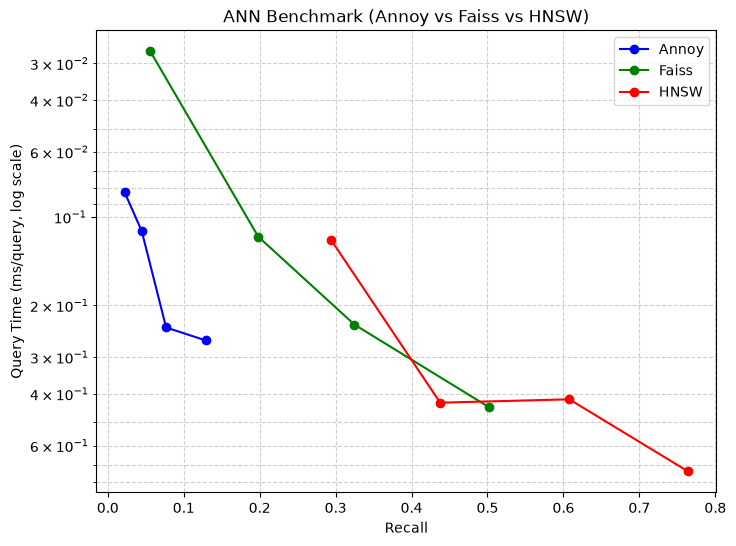

In [10]:
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt

# -------------------------------
# Dataset random
# -------------------------------
d = 128        # dimensi
nb = 100000    # jumlah database vector
nq = 1000      # jumlah query

np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')

# -------------------------------
# Ground truth dengan FAISS brute force
# -------------------------------
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10
_, gt_idx = index_flat.search(xq, k)

# -------------------------------
# Fungsi recall
# -------------------------------
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

# -------------------------------
# Benchmark Annoy
# -------------------------------
def run_annoy(xb, xq, n_trees=10, search_k=1000, k=10):
    f = xb.shape[1]
    index = AnnoyIndex(f, 'euclidean')
    for i, v in enumerate(xb):
        index.add_item(i, v)
    index.build(n_trees)

    start = time.time()
    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.time() - start) * 1000 / len(xq)  # ms/query
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark FAISS IVF
# -------------------------------
def run_faiss(xb, xq, nlist=100, nprobe=10, k=10):
    quantizer = faiss.IndexFlatL2(d)
    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
    index.train(xb)
    index.add(xb)

    index.nprobe = nprobe
    start = time.time()
    _, I = index.search(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark HNSW
# -------------------------------
def run_hnsw(xb, xq, ef=100, M=16, k=10):
    num_elements = xb.shape[0]
    p = hnswlib.Index(space='l2', dim=d)
    p.init_index(max_elements=num_elements, ef_construction=200, M=M)
    p.add_items(xb)
    p.set_ef(ef)

    start = time.time()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Jalankan benchmark dengan beberapa parameter
# -------------------------------
results = {"Annoy": [], "Faiss": [], "HNSW": []}

# Annoy
for sk in [200, 500, 1000, 2000]:
    rec, t = run_annoy(xb, xq, n_trees=10, search_k=sk)
    results["Annoy"].append((rec, t))
    print(f"Annoy  search_k={sk:4d} -> recall={rec:.4f} time={t:.4f} ms/query")

# FAISS
for npb in [1, 5, 10, 20]:
    rec, t = run_faiss(xb, xq, nlist=100, nprobe=npb)
    results["Faiss"].append((rec, t))
    print(f"FAISS  nprobe  ={npb:4d} -> recall={rec:.4f} time={t:.4f} ms/query")

# HNSW
for ef in [50, 100, 200, 400]:
    rec, t = run_hnsw(xb, xq, ef=ef)
    results["HNSW"].append((rec, t))
    print(f"HNSW   ef      ={ef:4d} -> recall={rec:.4f} time={t:.4f} ms/query")

# -------------------------------
# Visualisasi trade-off
# -------------------------------
plt.figure(figsize=(8,6))
for label, color in zip(results.keys(), ["blue","green","red"]):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker="o", label=label, color=color)

plt.xlabel("Recall")
plt.ylabel("Query Time (ms/query, log scale)")
plt.yscale("log")
plt.gca().invert_yaxis()  # invert Y, makin kanan makin turun
plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

### Analisis Grafik

Hasil benchmark (dataset 100rb vektor 128D, k=10):

| Library | Parameter terkecil → terbesar | Recall | Waktu (ms/query) |
|---|---|---|---|
| Annoy | search_k = 200 → 2000 | 0.022 → 0.129 | 0.082 → 0.263 |
| FAISS | nprobe = 1 → 20 | 0.056 → 0.502 | 0.027 → 0.444 |
| HNSW | ef = 50 → 400 | 0.294 → 0.764 | 0.120 → 0.735 |

Dari grafik dan tabel terlihat jelas **trade-off akurasi vs kecepatan** pada ketiga algoritma: semakin besar parameter pencarian (`search_k` pada Annoy, `nprobe` pada FAISS, `ef` pada HNSW), recall naik tetapi waktu query juga naik — kurva bergeser ke kanan bawah.

**HNSW paling mendekati posisi ideal (kanan atas)**: pada recall 0,76 ia hanya butuh ±0,74 ms/query, sementara untuk recall setara Annoy dan FAISS jauh lebih lambat atau bahkan tidak mampu mencapainya pada rentang parameter yang dicoba. Ini sesuai teori bahwa HNSW adalah *state-of-the-art* ANN — pada dimensi tinggi (128D) struktur graf hierarkisnya jauh lebih efektif daripada random projection tree (Annoy) maupun clustering IVF (FAISS). Annoy paling tertinggal: recall-nya baru 0,13 pada search_k=2000, karena pembagian ruang acak kurang efektif di ruang 128 dimensi.

## PRAKTIKUM 6 — Dataset Nyata: Micro Spotify (Kaggle)

Dataset: [Spotify Songs with Attributes and Lyrics](https://www.kaggle.com/datasets/bwandowando/spotify-songs-with-attributes-and-lyrics/data) (dataset pertama dari dua dataset), file `dataset/songs_with_attributes_and_lyrics.csv`.

Catatan: kolom `lyrics` tidak dipakai, jadi saat load CSV digunakan `usecols` agar hemat memori (file asli ±1,5 GB, mayoritas adalah teks lirik). Baris dengan nilai kosong pada fitur dibuang.

In [1]:
import pandas as pd
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# -------------------------------
# Load dataset
# -------------------------------
features = ['danceability', 'energy', 'loudness', 'speechiness',
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

df_full = pd.read_csv('dataset/songs_with_attributes_and_lyrics.csv',
                      usecols=features + ['name', 'artists'])
df_full = df_full.dropna(subset=features).reset_index(drop=True)
print("Jumlah data asli:", len(df_full))

# Sampling 100.000 lagu agar percobaan ringan dijalankan lokal
df = df_full.sample(n=100_000, random_state=42).reset_index(drop=True)
del df_full
print("Jumlah data (sampel):", len(df))
df.head()

Jumlah data asli: 955320
Jumlah data (sampel): 100000


,name,artists,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,Dans La Nuit,Sarah Brightman,0.325,0.291,-11.897,0.0349,0.968000,0.10900,0.1080,0.140,86.843
1,"Herbei, o ihr Gläubigen",Traditional;Friedrich Oberschelp;Christfried B...,0.325,0.107,-17.440,0.0389,0.983000,0.00000,0.1000,0.346,109.271
2,Who Am I?,Bazzi,0.592,0.514,-6.353,0.0329,0.517000,0.00000,0.1770,0.222,87.997
3,Stabwound Intercourse,Gorgasm,0.242,0.978,-7.627,0.1030,0.000022,0.86100,0.0941,0.193,105.342
4,Un Baile A Beneficio,Osvaldo Pugliese,0.709,0.403,-9.114,0.0678,0.966000,0.00009,0.0949,0.881,109.604


In [2]:
X = df[features].values

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10  # jumlah nearest neighbors

In [3]:
# -------------------------------
# Exact Nearest Neighbor (brute-force)
# -------------------------------
start = time.time()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
dist_exact, idx_exact = nn.kneighbors(X_scaled)
time_exact = time.time() - start
print(f"Exact NN done in {time_exact:.3f} s")

Exact NN done in 116.155 s


In [4]:
# -------------------------------
# Annoy
# -------------------------------
start = time.time()
f = X_scaled.shape[1]
index_annoy = AnnoyIndex(f, 'euclidean')
for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)
index_annoy.build(10)
idx_annoy = [index_annoy.get_nns_by_vector(v, k) for v in X_scaled]
time_annoy = time.time() - start
print(f"Annoy done in {time_annoy:.3f} s")

Annoy done in 9.404 s


In [5]:
# -------------------------------
# HNSW
# -------------------------------
start = time.time()
p_hnsw = hnswlib.Index(space='l2', dim=X_scaled.shape[1])
p_hnsw.init_index(max_elements=X_scaled.shape[0], ef_construction=200, M=16)
p_hnsw.add_items(X_scaled)
p_hnsw.set_ef(200)
idx_hnsw, dist_hnsw = p_hnsw.knn_query(X_scaled, k=k)
time_hnsw = time.time() - start
print(f"HNSW done in {time_hnsw:.3f} s")

HNSW done in 54.316 s


In [6]:
# -------------------------------
# FAISS IVF
# -------------------------------
start = time.time()
quantizer = faiss.IndexFlatL2(X_scaled.shape[1])
index_faiss = faiss.IndexIVFFlat(quantizer, X_scaled.shape[1], 100, faiss.METRIC_L2)
index_faiss.train(X_scaled)
index_faiss.add(X_scaled)
index_faiss.nprobe = 10
dist_faiss, idx_faiss = index_faiss.search(X_scaled, k)
time_faiss = time.time() - start
print(f"FAISS IVF done in {time_faiss:.3f} s")

FAISS IVF done in 19.571 s


In [7]:
# -------------------------------
# Contoh tampilkan top-5 neighbors dari item pertama
# -------------------------------
print("\nTop-5 neighbors for first song:")
print(f"Exact NN: {idx_exact[0][:5]}")
print(f"Annoy:    {idx_annoy[0][:5]}")
print(f"HNSW:     {idx_hnsw[0][:5]}")
print(f"FAISS:    {idx_faiss[0][:5]}")

print("\nLagu pertama:", df.loc[0, 'name'], "-", df.loc[0, 'artists'])
print("\n5 lagu paling mirip menurut Exact NN:")
print(df.loc[idx_exact[0][1:6], ['name', 'artists']].to_string())


Top-5 neighbors for first song:
Exact NN: [    0 39320 87041  6847 86813]
Annoy:    [0, 39320, 6847, 86813, 38532]
HNSW:     [    0 39320 87041  6847 86813]
FAISS:    [    0 39320 87041  6847 86813]



Lagu pertama: Dans La Nuit - Sarah Brightman

5 lagu paling mirip menurut Exact NN:


                            name                       artists
39320  Blue (with Sarah Vaughan)  Barry Manilow, Sarah Vaughan
87041                Revolutions                 Nobuo Uematsu
6847   This One's From The Heart      Tom Waits, Crystal Gayle
86813             MORNING PRAYER                Minako Yoshida
31093                    Waiting                   Alice Boman


In [8]:
# -------------------------------
# Evaluasi: recall@10 tiap metode ANN vs Exact NN (sampel 10.000 query)
# -------------------------------
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(X_scaled), size=10_000, replace=False)

def recall_at_k(pred, gt, idx, k):
    hits = sum(len(set(pred[i][:k]) & set(gt[i][:k])) for i in idx)
    return hits / (len(idx) * k)

rec_annoy = recall_at_k(idx_annoy, idx_exact, sample_idx, k)
rec_hnsw  = recall_at_k(idx_hnsw,  idx_exact, sample_idx, k)
rec_faiss = recall_at_k(idx_faiss, idx_exact, sample_idx, k)

print(f"Recall@10 Annoy : {rec_annoy:.4f}")
print(f"Recall@10 HNSW  : {rec_hnsw:.4f}")
print(f"Recall@10 FAISS : {rec_faiss:.4f}")

Recall@10 Annoy : 0.8644
Recall@10 HNSW  : 0.9997
Recall@10 FAISS : 0.9987


### Analisa

Percobaan pada dataset nyata Spotify (sampel 100.000 lagu, 9 fitur audio terstandarisasi, k=10):

| Metode | Waktu total (build + query seluruh data) | Recall@10 vs Exact NN |
|---|---|---|
| Exact NN (brute force) | 116.155 s | 1.0000 (acuan) |
| Annoy | 9.404 s | 0.8644 |
| HNSW | 54.316 s | 0.9997 |
| FAISS IVF | 19.571 s | 0.9987 |

**Analisa:**

1. **Peran StandardScaler** sangat penting di sini karena fitur audio punya skala sangat berbeda (misal `tempo` puluhan–ratusan BPM, `loudness` negatif, sedangkan `danceability` 0–1). Tanpa standarisasi, fitur berskala besar akan mendominasi jarak Euclidean sehingga "kemiripan" lagu jadi bias.

2. **Exact NN** adalah yang paling lambat (116 s) karena menghitung jarak setiap lagu ke seluruh 100rb lagu (brute force, ~10 miliar perhitungan jarak). Ia menjadi *ground truth* untuk mengukur recall metode lain.

3. **Annoy** paling cepat (9,4 s) tapi recall terendah (0,86) — sebagian tetangga yang ditemukan bukan tetangga exact. Terlihat pada lagu pertama: Annoy melewatkan urutan ke-3 dan memasukkan lagu lain (38532). Ini trade-off khas random projection tree.

4. **HNSW** mencapai recall nyaris sempurna (0,9997) — top-5 lagu pertama identik dengan exact — dengan waktu 54 s (mayoritas untuk build graf). Cocok untuk sistem yang index-nya dibangun sekali lalu dipakai jutaan query.

5. **FAISS IVF** menyeimbangkan keduanya: 19,6 s dengan recall 0,9987. Clustering IVF memangkas ruang pencarian secara drastis dengan akurasi yang tetap sangat tinggi.

Kesimpulan: pada data nyata pun pola dari Praktikum 5 terkonfirmasi — HNSW paling akurat, Annoy paling ringan, FAISS di tengah. Ketiganya jauh lebih cepat dari brute force dengan pengorbanan akurasi yang kecil (kecuali Annoy yang perlu lebih banyak tree/search_k untuk recall tinggi).

## TUGAS

Jalankan code berikut pada **Google Colab** dan **PyDroid3** (Android Python) di Smartphone Android. Bandingkan hasilnya dan tuliskan analisa, beserta spesifikasi smartphone yang digunakan.

In [9]:
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors
from annoy import AnnoyIndex
import hnswlib
import faiss
from sklearn.preprocessing import StandardScaler

# -------------------------------
# Contoh dataset kecil untuk testing
# -------------------------------
np.random.seed(42)
n_samples = 10000   # jumlah database vector
d = 128             # dimensi
X = np.random.random((n_samples, d)).astype('float32')

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10  # jumlah nearest neighbors

# -------------------------------
# Exact NN (brute-force)
# -------------------------------
start = time.time()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
dist_exact, idx_exact = nn.kneighbors(X_scaled)
time_exact = time.time() - start
print(f"Exact NN done in {time_exact:.3f} s")

# -------------------------------
# Annoy
# -------------------------------
start = time.time()
f = X_scaled.shape[1]
index_annoy = AnnoyIndex(f, 'euclidean')
for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)
index_annoy.build(10)
idx_annoy = [index_annoy.get_nns_by_vector(v, k) for v in X_scaled]
time_annoy = time.time() - start
print(f"Annoy done in {time_annoy:.3f} s")

# -------------------------------
# HNSW
# -------------------------------
start = time.time()
p_hnsw = hnswlib.Index(space='l2', dim=d)
p_hnsw.init_index(max_elements=n_samples, ef_construction=200, M=16)
p_hnsw.add_items(X_scaled)
p_hnsw.set_ef(200)
idx_hnsw, _ = p_hnsw.knn_query(X_scaled, k=k)
time_hnsw = time.time() - start
print(f"HNSW done in {time_hnsw:.3f} s")

# -------------------------------
# FAISS IVF
# -------------------------------
start = time.time()
quantizer = faiss.IndexFlatL2(d)
index_faiss = faiss.IndexIVFFlat(quantizer, d, 100, faiss.METRIC_L2)
index_faiss.train(X_scaled)
index_faiss.add(X_scaled)
index_faiss.nprobe = 10
_, idx_faiss = index_faiss.search(X_scaled, k)
time_faiss = time.time() - start
print(f"FAISS IVF done in {time_faiss:.3f} s")

# -------------------------------
# Tampilkan ringkasan waktu
# -------------------------------
print("\n=== Ringkasan Waktu (detik) ===")
print(f"Exact NN : {time_exact:.3f}")
print(f"Annoy    : {time_annoy:.3f}")
print(f"HNSW     : {time_hnsw:.3f}")
print(f"FAISS    : {time_faiss:.3f}")

Exact NN done in 3.744 s


Annoy done in 1.501 s


HNSW done in 18.386 s


FAISS IVF done in 3.058 s

=== Ringkasan Waktu (detik) ===
Exact NN : 3.744
Annoy    : 1.501
HNSW     : 18.386
FAISS    : 3.058


### Hasil Perbandingan

| Metode | Waktu (s) di komputer lokal | Waktu (s) di PyDroid3 |
|---|---|---|
| Exact NN | 3.744 | ... |
| Annoy | 1.501 | ... |
| HNSW | 18.386 | ... |
| FAISS IVF | 3.058 | ... |

*(kolom PyDroid3 diisi setelah menjalankan code yang sama di smartphone Android)*

**Spesifikasi smartphone:** ... *(merk/tipe, chipset, RAM, OS)*

**Analisa:** ... *(bandingkan waktu eksekusi komputer vs smartphone — umumnya smartphone jauh lebih lambat karena CPU mobile berdaya rendah dan tanpa optimasi BLAS/parallel sekuat PC; perhatikan juga urutan metode tercepat apakah sama di kedua perangkat)*